# Modelos de base: previsão de demanda e classificação do tipo de ocorrência

**Projeto Integrador IV (UNIVESP).** Continuação de `01_analise_exploratoria.ipynb`.

Este notebook treina e avalia os dois modelos propostos no relatório parcial:

1. **Regressão:** quantas ocorrências cada distrito terá na **próxima semana** (Random Forest Regressor).
2. **Classificação:** a que **grupo** pertence uma ocorrência (Estrutural, Arbóreo, Geológico, Hidrológico ou Outros), com a probabilidade de cada grupo (Random Forest Classifier).

As decisões de projeto vêm diretamente da análise exploratória:

- Só entram os **períodos com cadastro completo** (`PERIODOS_COMPLETOS` em `ml/limpeza.py`).
- A regressão é **semanal por distrito**, porque com 12 meses completos uma série mensal não se sustenta.
- A classificação usa os **5 grupos** de motivo, não os 11 motivos.
- **Todo modelo é comparado com referências simples.** Se não superá-las, o resultado é registrado assim mesmo.
- **Treino, validação e teste são separados por tempo**, nunca por sorteio. O teste é usado uma única vez, no fim.

O código reutilizável está em `ml/features.py` (variáveis) e `ml/modelos.py` (modelos, referências e métricas).

In [1]:
import sys
import json
from datetime import datetime
from pathlib import Path

if "google.colab" in sys.modules:
    if not Path("defesa2.0").exists():
        !git clone -q https://github.com/allanwds/defesa2.0.git
    RAIZ = Path("defesa2.0").resolve()
else:
    RAIZ = Path.cwd().resolve()
    while not (RAIZ / "ml").is_dir() and RAIZ != RAIZ.parent:
        RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import classification_report, confusion_matrix, log_loss

from ml import modelos as M
from ml.dados import carregar_ocorrencias
from ml.features import VARIAVEIS_CLASSIFICACAO, VARIAVEIS_REGRESSAO, painel_semanal, tabela_classificacao
from ml.limpeza import PERIODOS_COMPLETOS, limpar, marcar_periodos, ocorrencias_validas

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda v: f"{v:.3f}")

TEXTO, TEXTO_SEC, GRADE = "#0b0b0b", "#52514e", "#e4e3df"
AZUL, LARANJA, VERDE, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#c9c8c2"
MESES = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": GRADE,
    "axes.labelcolor": TEXTO_SEC,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.axisbelow": True,
    "grid.color": GRADE,
    "grid.linewidth": 0.8,
    "xtick.color": TEXTO_SEC,
    "ytick.color": TEXTO_SEC,
    "legend.frameon": False,
    "font.size": 10,
})


def barras_horizontais(serie, titulo, xlabel, formato="{:.3f}"):
    serie = serie.sort_values()
    fig, ax = plt.subplots(figsize=(7.5, 0.45 * len(serie) + 1.2))
    ax.barh(serie.index, serie.values, height=0.6, color=AZUL)
    for y, v in enumerate(serie.values):
        ax.annotate(formato.format(v).replace(".", ","), (max(v, 0), y), xytext=(4, 0), textcoords="offset points",
                    va="center", fontsize=9, color=TEXTO_SEC)
    ax.axvline(0, color=TEXTO_SEC, linewidth=0.8)
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
    ax.set_title(titulo)
    ax.set_xlim(min(0, serie.min() * 1.2), serie.max() * 1.25)
    plt.show()


print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


## 1. Dados e protocolo de avaliação

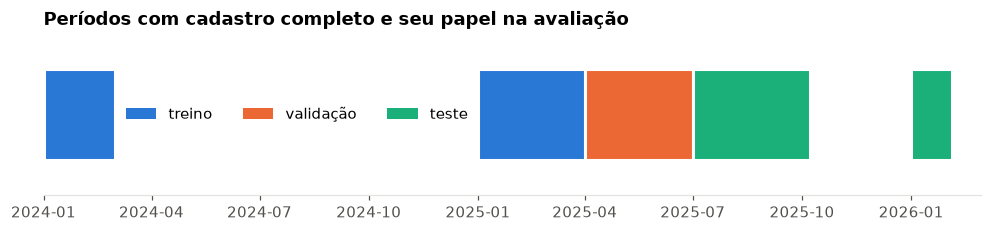

   treino: 368 ocorrências
validação: 117 ocorrências
    teste: 282 ocorrências


In [2]:
oc = marcar_periodos(ocorrencias_validas(limpar(carregar_ocorrencias())))

INICIO_VALIDACAO = pd.Timestamp("2025-04-01")
INICIO_TESTE = pd.Timestamp("2025-07-01")

fig, ax = plt.subplots(figsize=(11, 1.9))
papeis = [("treino", None, INICIO_VALIDACAO, AZUL), ("validação", INICIO_VALIDACAO, INICIO_TESTE, LARANJA),
          ("teste", INICIO_TESTE, None, VERDE)]
for inicio, fim in PERIODOS_COMPLETOS:
    inicio, fim = pd.Timestamp(inicio), pd.Timestamp(fim)
    for nome, ini_papel, fim_papel, cor in papeis:
        a = max(inicio, ini_papel) if ini_papel is not None else inicio
        b = min(fim, fim_papel - pd.Timedelta(days=1)) if fim_papel is not None else fim
        if a <= b:
            ax.barh(0, (b - a).days + 1, left=a, height=0.5, color=cor, edgecolor="white", linewidth=2)
for nome, _, _, cor in papeis:
    ax.barh(0, 0, color=cor, label=nome)
ax.set_yticks([])
ax.grid(False)
ax.spines["left"].set_visible(False)
ax.set_xlim(pd.Timestamp("2024-01-01"), pd.Timestamp("2026-03-01"))
ax.legend(loc="center", ncol=3, bbox_to_anchor=(0.27, 0.5))
ax.set_title("Períodos com cadastro completo e seu papel na avaliação")
plt.show()

for nome, filtro in [("treino", oc["data"] < INICIO_VALIDACAO),
                     ("validação", (oc["data"] >= INICIO_VALIDACAO) & (oc["data"] < INICIO_TESTE)),
                     ("teste", oc["data"] >= INICIO_TESTE)]:
    print(f"{nome:>9}: {(filtro & oc['periodo_completo']).sum()} ocorrências")

- **Treino:** janeiro e fevereiro de 2024 e janeiro a março de 2025.
- **Validação:** abril a junho de 2025. Serve apenas para escolher os hiperparâmetros.
- **Teste:** de julho a 7 de outubro de 2025 e janeiro de 2026. É usado **uma única vez**, depois de todas as escolhas feitas.

O teste mistura meses secos (julho a setembro) com o início da estação chuvosa (outubro e janeiro). Isso é bom, porque o modelo precisa funcionar nas duas situações.

## 2. Regressão: ocorrências por semana e distrito

### 2.1 Tabela de treino

Cada linha é uma semana completa (segunda a domingo) em um distrito. As variáveis usam só informação disponível **antes** da semana prevista:

| Variável | Significado |
|---|---|
| `lag1` | ocorrências no distrito na semana anterior |
| `media4` | média das até 4 semanas anteriores no distrito |
| `total_lag1` | ocorrências nos dois distritos na semana anterior |
| `sao_luis` | 1 para Jardim São Luís, 0 para Jardim Ângela |
| `estacao_chuvosa` | 1 de outubro a março |
| `verao` | 1 em janeiro e fevereiro |

In [3]:
painel = painel_semanal(oc)
print(f"{len(painel)} linhas ({painel['semana'].nunique()} semanas × 2 distritos)")
painel.head()

96 linhas (48 semanas × 2 distritos)


,semana,bloco,distrito,ocorrencias,lag1,media4,total_lag1,sao_luis,estacao_chuvosa,verao
0,2024-01-08,0,Jardim São Luís,6,4.000,4.000,8.000,1,1,1
1,2024-01-15,0,Jardim São Luís,7,6.000,5.000,15.000,1,1,1
2,2024-01-22,0,Jardim São Luís,6,7.000,5.667,21.000,1,1,1
3,2024-01-29,0,Jardim São Luís,6,6.000,5.750,11.000,1,1,1
4,2024-02-05,0,Jardim São Luís,6,6.000,6.250,11.000,1,1,1


### 2.2 Avaliação passo a passo

Na prática, o modelo seria usado toda segunda-feira para prever a semana que começa. A avaliação imita isso: para cada semana avaliada, o modelo é treinado com **todas as semanas anteriores** e prevê só aquela semana (*walk-forward*).

As três referências simples são:

- **última semana:** repete a contagem da semana anterior;
- **média móvel:** média das 4 semanas anteriores;
- **média histórica:** média semanal do distrito em todo o histórico.

### 2.3 Escolha do hiperparâmetro na validação

O principal controle de complexidade do Random Forest com poucos dados é `min_samples_leaf`, o número mínimo de semanas em cada folha das árvores. Valores maiores produzem previsões mais suaves.

In [4]:
semanas = np.sort(painel["semana"].unique())
semanas_validacao = semanas[(semanas >= INICIO_VALIDACAO) & (semanas < INICIO_TESTE)]
semanas_teste = semanas[semanas >= INICIO_TESTE]

REFERENCIAS_REG = {
    "última semana": M.UltimaSemana,
    "média móvel (4 sem.)": M.MediaMovel,
    "média histórica": M.MediaHistorica,
}
CANDIDATOS_REG = {f"RF min_samples_leaf={n}": (lambda n=n: M.regressor(n)) for n in (1, 3, 5, 10, 20)}

val_reg = M.previsao_passo_a_passo(painel, semanas_validacao, CANDIDATOS_REG | REFERENCIAS_REG, VARIAVEIS_REGRESSAO)
tabela_val_reg = pd.DataFrame({nome: M.metricas_regressao(val_reg["ocorrencias"], val_reg[nome])
                               for nome in CANDIDATOS_REG | REFERENCIAS_REG}).T
escolhido_reg = tabela_val_reg.loc[list(CANDIDATOS_REG), "MAE"].idxmin()
MIN_LEAF_REG = int(escolhido_reg.split("=")[1])

print(f"Validação: {len(semanas_validacao)} semanas. Escolhido: {escolhido_reg}")
tabela_val_reg.sort_values("MAE")

Validação: 13 semanas. Escolhido: RF min_samples_leaf=10


,MAE,RMSE
média móvel (4 sem.),2.904,3.629
RF min_samples_leaf=10,3.217,3.861
última semana,3.308,4.270
RF min_samples_leaf=1,3.572,4.015
RF min_samples_leaf=5,3.585,4.526
RF min_samples_leaf=3,3.878,4.955
RF min_samples_leaf=20,4.223,4.705
média histórica,4.555,4.981


Na validação, `min_samples_leaf=10` foi o melhor Random Forest, mas a **média móvel ganhou de todos**. Isso é um alerta honesto: com tão poucas semanas de treino (de 19 a 31 por distrito ao longo da validação), o modelo ainda não tem dados suficientes para superar com segurança uma regra simples. A configuração escolhida segue para o teste sem nenhum outro ajuste.

### 2.4 Resultado no teste

In [5]:
MODELO_REG = f"Random Forest (min_samples_leaf={MIN_LEAF_REG})"
teste_reg = M.previsao_passo_a_passo(painel, semanas_teste, {MODELO_REG: lambda: M.regressor(MIN_LEAF_REG)} | REFERENCIAS_REG,
                                     VARIAVEIS_REGRESSAO)
tabela_teste_reg = pd.DataFrame({nome: M.metricas_regressao(teste_reg["ocorrencias"], teste_reg[nome])
                                 for nome in [MODELO_REG, *REFERENCIAS_REG]}).T.sort_values("MAE")

melhor_ref = tabela_teste_reg.loc[list(REFERENCIAS_REG), "MAE"].idxmin()
ganho = 1 - tabela_teste_reg.loc[MODELO_REG, "MAE"] / tabela_teste_reg.loc[melhor_ref, "MAE"]
print(f"Teste: {len(semanas_teste)} semanas × 2 distritos = {len(teste_reg)} previsões")
print(f"Média real: {teste_reg['ocorrencias'].mean():.1f} ocorrências por semana e distrito")
print(f"Erro do modelo {ganho:+.0%} menor que o da melhor referência ({melhor_ref})")
tabela_teste_reg

Teste: 16 semanas × 2 distritos = 32 previsões
Média real: 7.5 ocorrências por semana e distrito
Erro do modelo +12% menor que o da melhor referência (média móvel (4 sem.))


,MAE,RMSE
Random Forest (min_samples_leaf=10),3.172,4.219
média móvel (4 sem.),3.589,4.779
média histórica,4.313,5.371
última semana,4.438,5.755


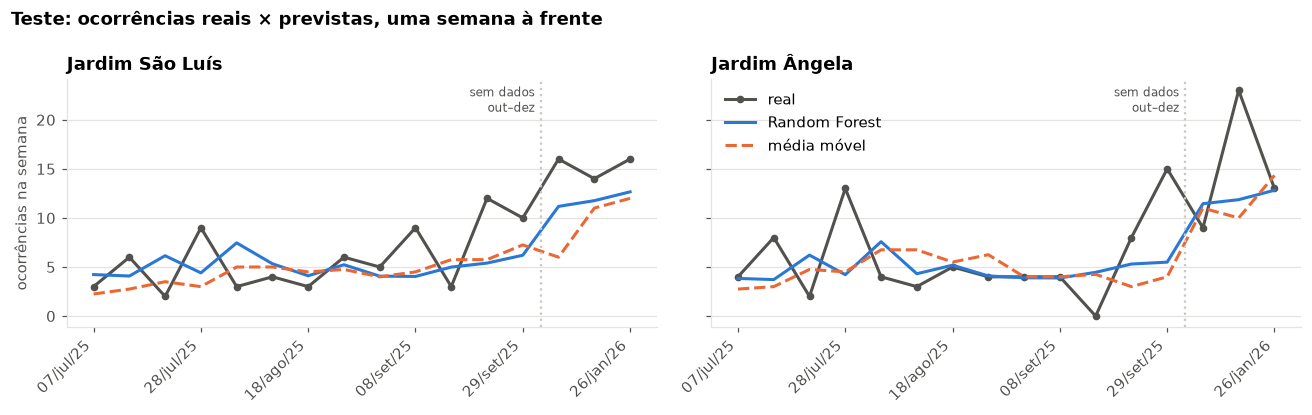

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (distrito, d) in zip(axes, teste_reg.groupby("distrito")):
    d = d.sort_values("semana")
    x = np.arange(len(d))
    ax.plot(x, d["ocorrencias"], color=TEXTO_SEC, linewidth=2, marker="o", markersize=4, label="real")
    ax.plot(x, d[MODELO_REG], color=AZUL, linewidth=2, label="Random Forest")
    ax.plot(x, d["média móvel (4 sem.)"], color=LARANJA, linewidth=2, linestyle="--", label="média móvel")
    rotulos = [f"{s.day:02d}/{MESES[s.month - 1]}/{str(s.year)[2:]}" for s in d["semana"]]
    ax.set_xticks(x[::3], rotulos[::3], rotation=45, ha="right")
    quebra = np.flatnonzero(np.diff(d["bloco"].to_numpy()))[0] + 0.5
    ax.axvline(quebra, color=CINZA, linewidth=1.5, linestyle=":")
    ax.annotate("sem dados\nout–dez", (quebra, 1), xycoords=("data", "axes fraction"), xytext=(-4, -4), textcoords="offset points",
                ha="right", va="top", fontsize=8, color=TEXTO_SEC)
    ax.set_title(distrito)
axes[0].set_ylabel("ocorrências na semana")
axes[1].legend(loc="upper left")
fig.suptitle("Teste: ocorrências reais × previstas, uma semana à frente", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
plt.show()

O modelo acompanha o nível de cada distrito e reage mais rápido que a média móvel quando a demanda muda de patamar, como na entrada de janeiro de 2026. Mas não antecipa os picos isolados (por exemplo, a semana de 23 ocorrências no Jardim Ângela em janeiro), porque nenhuma das variáveis atuais sabe que vai chover. A chuva é a candidata natural para explicar esses picos (notebook 03).

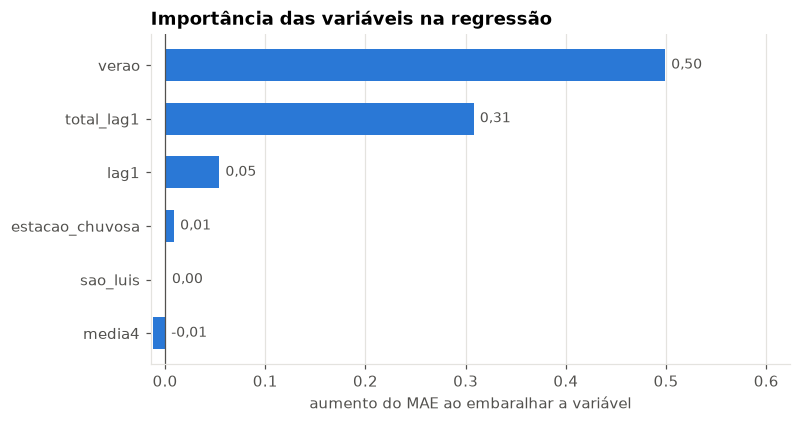

In [7]:
treino_reg = painel[painel["semana"] < INICIO_TESTE]
alvo_reg = painel[painel["semana"] >= INICIO_TESTE]
modelo_reg = M.regressor(MIN_LEAF_REG).fit(treino_reg[VARIAVEIS_REGRESSAO], treino_reg["ocorrencias"])
imp_reg = permutation_importance(modelo_reg, alvo_reg[VARIAVEIS_REGRESSAO], alvo_reg["ocorrencias"],
                                 scoring="neg_mean_absolute_error", n_repeats=50, random_state=M.SEMENTE)
barras_horizontais(pd.Series(imp_reg.importances_mean, VARIAVEIS_REGRESSAO),
                   "Importância das variáveis na regressão", "aumento do MAE ao embaralhar a variável", "{:.2f}")

A importância por permutação mede quanto o erro aumenta quando uma variável é embaralhada no teste.

- `verao` é a mais importante. O modelo aprendeu com janeiro e fevereiro de 2024 e 2025 que as semanas de verão têm mais ocorrências, e é isso que o faz subir antes da média móvel em janeiro de 2026. Essa importância vem de apenas 4 semanas de verão no teste, então é um sinal promissor, mas frágil.
- `total_lag1` (a semana anterior somando os dois distritos) é mais útil que a defasagem de cada distrito isolado. Somar os distritos reduz o ruído.
- `media4` fica perto de zero porque repete a informação de `lag1` e `total_lag1`.

O verão funciona aqui como um substituto grosseiro da chuva. Uma variável de chuva real deve ocupar esse papel com muito mais precisão.

## 3. Classificação: grupo do motivo

### 3.1 Tabela de treino

Cada linha é uma ocorrência. As variáveis descrevem **onde** e **quando** ela aconteceu:

| Variável | Significado |
|---|---|
| `area_risco` | classificação de risco do local (0 = NDA, 1 a 4 = R1 a R4) |
| `latitude`, `longitude` | posição (coordenadas inválidas são imputadas pela mediana) |
| `sao_luis` | distrito |
| `estacao_chuvosa`, `verao` | época do ano |
| `dia_util` | 1 de segunda a sexta |

O mês exato não entra como variável, porque o treino só cobre janeiro a junho e o modelo nunca veria os meses de julho a dezembro. A estação chuvosa e o verão generalizam melhor.

In [8]:
tabela = tabela_classificacao(oc)
treino_cls = tabela[tabela["data"] < INICIO_VALIDACAO]
validacao_cls = tabela[(tabela["data"] >= INICIO_VALIDACAO) & (tabela["data"] < INICIO_TESTE)]
teste_cls = tabela[tabela["data"] >= INICIO_TESTE]

pd.DataFrame({
    "treino": treino_cls["grupo_motivo"].value_counts(),
    "validação": validacao_cls["grupo_motivo"].value_counts(),
    "teste": teste_cls["grupo_motivo"].value_counts(),
}).loc[["Estrutural", "Arbóreo", "Geológico", "Hidrológico", "Outros"]]

,treino,validação,teste
grupo_motivo,,,
Estrutural,124,52,90
Arbóreo,108,21,96
Geológico,69,13,21
Hidrológico,18,4,16
Outros,49,27,59


### 3.2 Escolha dos hiperparâmetros na validação

São testadas combinações de `min_samples_leaf` e `max_features` (quantas variáveis cada divisão das árvores pode considerar). O critério é o **F1 macro**, que dá o mesmo peso a todas as classes. Com classes desbalanceadas, a acurácia premiaria um modelo que só acerta as classes grandes.

In [9]:
resultados = []
for folha in (1, 3, 5, 10, 20):
    for max_features in ("sqrt", None):
        modelo = M.ClassificadorGrupo(folha, max_features).fit(treino_cls[VARIAVEIS_CLASSIFICACAO], treino_cls["grupo_motivo"])
        metricas = M.metricas_classificacao(validacao_cls["grupo_motivo"], modelo.predict(validacao_cls[VARIAVEIS_CLASSIFICACAO]),
                                            modelo.predict_proba(validacao_cls[VARIAVEIS_CLASSIFICACAO]), modelo.classes_)
        resultados.append({"min_samples_leaf": folha, "max_features": max_features or "todas", **metricas})

tabela_val_cls = pd.DataFrame(resultados).sort_values(["F1 macro", "log loss"], ascending=[False, True])
melhor_cls = tabela_val_cls.iloc[0]
MIN_LEAF_CLS = int(melhor_cls["min_samples_leaf"])
MAX_FEATURES_CLS = None if melhor_cls["max_features"] == "todas" else melhor_cls["max_features"]
print(f"Escolhido: min_samples_leaf={MIN_LEAF_CLS}, max_features={melhor_cls['max_features']}")
tabela_val_cls.reset_index(drop=True)

Escolhido: min_samples_leaf=10, max_features=todas


,min_samples_leaf,max_features,acurácia,acurácia balanceada,F1 macro,log loss
0,10,todas,0.333,0.332,0.287,1.541
1,10,sqrt,0.316,0.318,0.287,1.426
2,5,sqrt,0.325,0.315,0.275,1.429
3,3,sqrt,0.316,0.304,0.267,1.441
4,20,sqrt,0.291,0.296,0.266,1.435
5,3,todas,0.282,0.270,0.246,1.870
6,5,todas,0.265,0.267,0.238,1.608
7,20,todas,0.239,0.314,0.228,1.508
8,1,todas,0.256,0.219,0.207,2.207
9,1,sqrt,0.282,0.209,0.199,2.381


- Árvores sem restrição (`min_samples_leaf=1`) decoram o treino e têm o pior desempenho. A regularização (folhas com pelo menos 10 ocorrências) é o que mais ajuda, como esperado com menos de 400 exemplos de treino.
- As duas melhores configurações empatam na prática em F1 macro (0,287). Pela regra definida antes de rodar (maior F1 macro, desempate pelo log loss), ficou a com todas as variáveis por divisão. A outra (`sqrt`) tem probabilidades melhores na validação, uma escolha que pode ser revista quando houver mais dados.

### 3.3 Resultado no teste

O modelo é retreinado com treino e validação juntos (tudo antes de julho de 2025) e avaliado uma única vez no teste. Há duas referências:

- **classe mais frequente:** chuta sempre o grupo mais comum e usa as proporções do treino como probabilidade;
- **sorteio estratificado:** sorteia um grupo respeitando as proporções do treino.

In [10]:
treino_final_cls = tabela[tabela["data"] < INICIO_TESTE]
X_treino, y_treino = treino_final_cls[VARIAVEIS_CLASSIFICACAO], treino_final_cls["grupo_motivo"]
X_teste, y_teste = teste_cls[VARIAVEIS_CLASSIFICACAO], teste_cls["grupo_motivo"]

modelo_cls = M.ClassificadorGrupo(MIN_LEAF_CLS, MAX_FEATURES_CLS).fit(X_treino, y_treino)
mais_frequente = M.ClasseMaisFrequente().fit(X_treino, y_treino)
sorteio = DummyClassifier(strategy="stratified", random_state=M.SEMENTE).fit(X_treino, y_treino)

tabela_teste_cls = pd.DataFrame({
    "Random Forest": M.metricas_classificacao(y_teste, modelo_cls.predict(X_teste), modelo_cls.predict_proba(X_teste),
                                              modelo_cls.classes_),
    "classe mais frequente": M.metricas_classificacao(y_teste, mais_frequente.predict(X_teste),
                                                      mais_frequente.predict_proba(X_teste), mais_frequente.classes_),
    "sorteio estratificado": M.metricas_classificacao(y_teste, sorteio.predict(X_teste), sorteio.predict_proba(X_teste),
                                                      sorteio.classes_),
}).T
tabela_teste_cls.loc["sorteio estratificado", "log loss"] = np.nan  # probabilidades 0/1: log loss não se aplica
print(f"Teste: {len(teste_cls)} ocorrências")
tabela_teste_cls

Teste: 282 ocorrências


,acurácia,acurácia balanceada,F1 macro,log loss
Random Forest,0.326,0.323,0.281,1.389
classe mais frequente,0.319,0.200,0.097,1.470
sorteio estratificado,0.241,0.182,0.175,NaN


              precision    recall  f1-score   support

     Arbóreo       0.50      0.54      0.52        96
  Estrutural       0.21      0.09      0.12        90
   Geológico       0.09      0.19      0.12        21
 Hidrológico       0.23      0.44      0.30        16
      Outros       0.33      0.36      0.34        59

    accuracy                           0.33       282
   macro avg       0.27      0.32      0.28       282
weighted avg       0.32      0.33      0.31       282



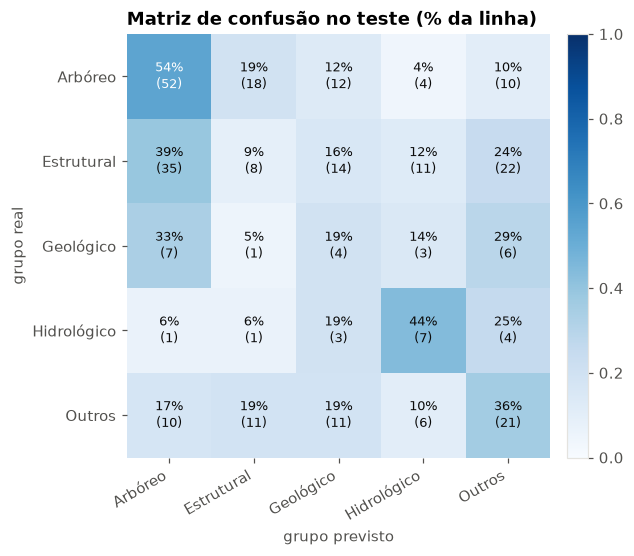

In [11]:
print(classification_report(y_teste, modelo_cls.predict(X_teste), digits=2, zero_division=0))

classes = list(modelo_cls.classes_)
matriz = confusion_matrix(y_teste, modelo_cls.predict(X_teste), labels=classes)
proporcao = matriz / matriz.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(proporcao, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(classes)), classes, rotation=30, ha="right")
ax.set_yticks(range(len(classes)), classes)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
for i in range(len(classes)):
    for j in range(len(classes)):
        ax.text(j, i, f"{proporcao[i, j]:.0%}\n({matriz[i, j]})", ha="center", va="center", fontsize=8.5,
                color="white" if proporcao[i, j] > 0.5 else TEXTO)
ax.set_xlabel("grupo previsto")
ax.set_ylabel("grupo real")
ax.set_title("Matriz de confusão no teste (% da linha)")
plt.colorbar(im, ax=ax, fraction=0.04, pad=0.03)
plt.show()

- O modelo supera as duas referências em F1 macro (0,28 contra 0,10 e 0,18) e acurácia balanceada. A acurácia, porém, fica praticamente igual à de chutar sempre a classe mais frequente (33% contra 32%). O desempenho absoluto é **modesto**.
- **Arbóreo** é o grupo mais bem reconhecido (54% de revocação): ocorre fora de áreas de risco, o que o distingue dos demais.
- **Hidrológico** acerta 44%, apesar de ser a menor classe, porque se concentra em áreas R3/R4 e em trechos específicos do mapa.
- **Estrutural** é o pior (9%). Desabamentos e rachaduras acontecem nos mesmos lugares e épocas que as quedas de árvore, e o modelo os confunde com Arbóreo (39%) e Outros (24%). Com as variáveis atuais não há como separá-los. Seria preciso informação sobre o imóvel ou uma descrição da ocorrência.

### 3.4 Probabilidades por cenário

O relatório parcial promete "estimar as probabilidades associadas às categorias de eventos mais esperadas". O treino com pesos balanceados faz o modelo agir como se as cinco classes fossem igualmente comuns. Por isso as probabilidades são reajustadas às proporções reais (`ClassificadorGrupo.predict_proba`). O log loss mede a qualidade das probabilidades: quanto menor, melhor.

In [12]:
pd.Series({
    "Random Forest, probabilidades reajustadas": log_loss(y_teste, modelo_cls.predict_proba(X_teste), labels=classes),
    "Random Forest, sem reajuste": log_loss(y_teste, modelo_cls.predict_proba_balanceada(X_teste), labels=classes),
    "proporções do treino (referência)": log_loss(y_teste, mais_frequente.predict_proba(X_teste), labels=classes),
}, name="log loss no teste").to_frame()

,log loss no teste
"Random Forest, probabilidades reajustadas",1.389
"Random Forest, sem reajuste",1.457
proporções do treino (referência),1.470


In [13]:
centro = treino_final_cls.groupby("sao_luis")[["latitude", "longitude"]].median()


def cenario(nome, area_risco, chuvosa, verao, sao_luis):
    return {"cenário": nome, "area_risco": area_risco, "estacao_chuvosa": chuvosa, "verao": verao, "dia_util": 1,
            "sao_luis": sao_luis, "latitude": centro.loc[sao_luis, "latitude"], "longitude": centro.loc[sao_luis, "longitude"]}


cenarios = pd.DataFrame([
    cenario("Jd. Ângela, verão, área R3", 3, 1, 1, 0),
    cenario("Jd. Ângela, verão, sem área de risco", 0, 1, 1, 0),
    cenario("Jd. Ângela, estação seca, área R3", 3, 0, 0, 0),
    cenario("Jd. São Luís, estação seca, sem área de risco", 0, 0, 0, 1),
]).set_index("cenário")

probabilidades = pd.DataFrame(modelo_cls.predict_proba(cenarios[VARIAVEIS_CLASSIFICACAO]), index=cenarios.index,
                              columns=classes)
probabilidades.style.format("{:.0%}").background_gradient(cmap="Blues", vmin=0, vmax=0.6, axis=None)

,Arbóreo,Estrutural,Geológico,Hidrológico,Outros
cenário,,,,,
"Jd. Ângela, verão, área R3",17%,29%,39%,1%,15%
"Jd. Ângela, verão, sem área de risco",54%,26%,15%,0%,4%
"Jd. Ângela, estação seca, área R3",19%,27%,27%,1%,27%
"Jd. São Luís, estação seca, sem área de risco",35%,32%,14%,1%,17%


Para um local e uma época, o modelo devolve a distribuição esperada dos tipos de ocorrência. Os cenários usam o ponto central de cada distrito.

- **Fora de áreas de risco, no verão,** predomina o Arbóreo (54%).
- **Em área R3, no verão,** o Geológico passa a ser o mais provável (39%).
- **Na estação seca,** as probabilidades ficam mais espalhadas.
- **O Hidrológico fica perto de zero em todos os cenários,** porque depende de trechos específicos do mapa (margens de córrego, baixadas) e o centro do distrito não está neles. Isso mostra que o modelo usa a posição, mas também que precisa de variáveis que descrevam o terreno de verdade.

### 3.5 Importância das variáveis

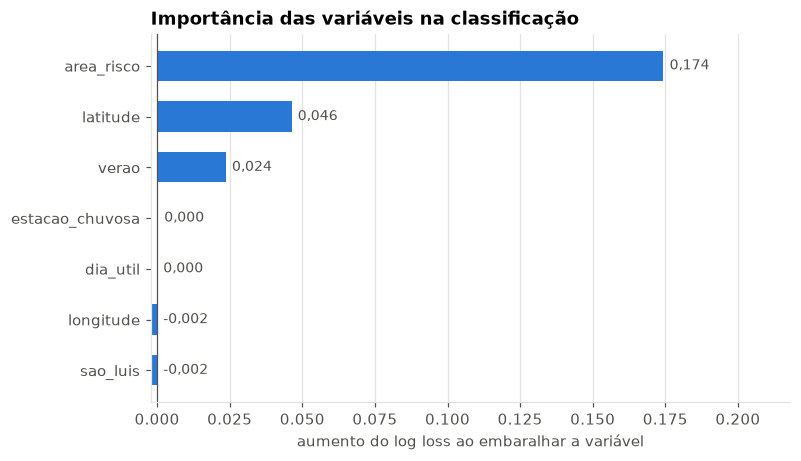

In [14]:
imp_cls = permutation_importance(modelo_cls, X_teste, y_teste, scoring="neg_log_loss", n_repeats=50,
                                 random_state=M.SEMENTE)
barras_horizontais(pd.Series(imp_cls.importances_mean, VARIAVEIS_CLASSIFICACAO),
                   "Importância das variáveis na classificação", "aumento do log loss ao embaralhar a variável")

A área de risco é de longe a variável mais útil, seguida pela latitude e pelo verão. Longitude, distrito, dia útil e estação chuvosa ficam perto de zero: embaralhá-las não piora o teste. Melhorar a classificação passa por **mais informação sobre o local** (declividade, proximidade de córregos, mapeamento de risco do GeoSampa) e **sobre o evento** (chuva no dia, descrição da ocorrência).

## 4. Conclusões

### Resultados

| Modelo | Métrica no teste | Random Forest | Melhor referência |
|---|---|---|---|
| Regressão (semana seguinte, por distrito) | MAE | **3,17** | 3,59 (média móvel) |
| Classificação (5 grupos) | F1 macro | **0,28** | 0,18 (sorteio estratificado) |
| Classificação (5 grupos) | log loss | **1,39** | 1,47 (proporções do treino) |
| Classificação (5 grupos) | acurácia | 33% | 32% (classe mais frequente) |

- **Regressão.** O Random Forest errou 12% menos que a média móvel no teste. Na validação, porém, a média móvel venceu. Com 32 previsões de teste, essa diferença é um **indício, não uma prova**. O ganho vem principalmente do verão, que funciona como um substituto grosseiro da chuva.
- **Classificação.** O modelo supera as referências nas métricas que importam para classes desbalanceadas (F1 macro, acurácia balanceada e log loss), mas a acurácia é praticamente a de um chute. Ele é útil para **Arbóreo** e **Hidrológico** e quase cego para **Estrutural**.

### Leitura geral

A metodologia está pronta e é defensável: separação temporal, hiperparâmetros escolhidos sem tocar no teste, comparação com referências simples e probabilidades reajustadas. **O fator limitante é o dado**: são poucas semanas e as variáveis não descrevem o que causa as ocorrências.

### Limitações

- A regressão depende das contagens das semanas anteriores. Como a base para em fevereiro de 2026, previsões para semanas posteriores usariam semanas incompletas e tenderiam a subestimar a demanda.
- A classificação não depende das semanas anteriores, mas usa só local e época: com essas variáveis, o grupo Estrutural é quase indistinguível dos demais.

## 5. Modelos finais

Os dois modelos são retreinados com **todos** os períodos completos, com os hiperparâmetros escolhidos na validação. Eles são salvos em `ml/modelos/` (fora do git) junto com os metadados: data de treino, variáveis, hiperparâmetros e métricas de teste.

In [15]:
DIR_MODELOS = RAIZ / "ml" / "modelos"
DIR_MODELOS.mkdir(exist_ok=True)
gerado_em = datetime.now().isoformat(timespec="seconds")

final_reg = M.regressor(MIN_LEAF_REG).fit(painel[VARIAVEIS_REGRESSAO], painel["ocorrencias"])
final_cls = M.ClassificadorGrupo(MIN_LEAF_CLS, MAX_FEATURES_CLS).fit(tabela[VARIAVEIS_CLASSIFICACAO], tabela["grupo_motivo"])

metadados = {
    "gerado_em": gerado_em,
    "scikit_learn": sklearn.__version__,
    "periodos_completos": PERIODOS_COMPLETOS,
    "regressao": {
        "arquivo": "regressao_semanal.joblib",
        "alvo": "ocorrências na semana seguinte, por distrito",
        "variaveis": VARIAVEIS_REGRESSAO,
        "min_samples_leaf": MIN_LEAF_REG,
        "linhas_treino": len(painel),
        "teste": {k: round(float(v), 3) for k, v in tabela_teste_reg.loc[MODELO_REG].items()},
        "teste_melhor_referencia": {"nome": melhor_ref,
                                    **{k: round(float(v), 3) for k, v in tabela_teste_reg.loc[melhor_ref].items()}},
    },
    "classificacao": {
        "arquivo": "classificacao_grupo.joblib",
        "alvo": "grupo do motivo",
        "classes": list(final_cls.classes_),
        "variaveis": VARIAVEIS_CLASSIFICACAO,
        "min_samples_leaf": MIN_LEAF_CLS,
        "max_features": MAX_FEATURES_CLS or "todas",
        "linhas_treino": len(tabela),
        "teste": {k: round(float(v), 3) for k, v in tabela_teste_cls.loc["Random Forest"].items()},
    },
}

joblib.dump(final_reg, DIR_MODELOS / metadados["regressao"]["arquivo"])
joblib.dump(final_cls, DIR_MODELOS / metadados["classificacao"]["arquivo"])
(DIR_MODELOS / "metadados.json").write_text(json.dumps(metadados, ensure_ascii=False, indent=2))
print(json.dumps(metadados, ensure_ascii=False, indent=2))

{
  "gerado_em": "2026-10-18T20:58:29",
  "scikit_learn": "1.9.1",
  "periodos_completos": [
    [
      "2024-01-01",
      "2024-02-29"
    ],
    [
      "2025-01-01",
      "2025-10-07"
    ],
    [
      "2026-01-01",
      "2026-02-03"
    ]
  ],
  "regressao": {
    "arquivo": "regressao_semanal.joblib",
    "alvo": "ocorrências na semana seguinte, por distrito",
    "variaveis": [
      "sao_luis",
      "estacao_chuvosa",
      "verao",
      "lag1",
      "media4",
      "total_lag1"
    ],
    "min_samples_leaf": 10,
    "linhas_treino": 96,
    "teste": {
      "MAE": 3.172,
      "RMSE": 4.219
    },
    "teste_melhor_referencia": {
      "nome": "média móvel (4 sem.)",
      "MAE": 3.589,
      "RMSE": 4.779
    }
  },
  "classificacao": {
    "arquivo": "classificacao_grupo.joblib",
    "alvo": "grupo do motivo",
    "classes": [
      "Arbóreo",
      "Estrutural",
      "Geológico",
      "Hidrológico",
      "Outros"
    ],
    "variaveis": [
      "area_risco",
     